# 04 — Tuning theo thời gian, chọn mô hình, Test và phân tích lỗi

Grid search dùng **một holdout Validation theo thời gian**, không phải k-fold GridSearchCV. Tiêu chí chọn là RMSE BRL. Tuning chỉ áp dụng cho Random Forest trong luồng hiện tại; so sánh candidate đã tuning với toàn bộ candidates và baselines từ notebook 03 trước khi mở Test.

In [1]:
get_ipython().run_line_magic("matplotlib", "inline")
import sys
import json
import pickle
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from IPython.display import display, Markdown

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/config.py").exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src import config
from src.data.loader import load_raw_sales_data
from src.data.builder import build_weekly_sales_dataset
from src.data.preprocessing import CustomDataPipeline, weekly_split_data
from src.models import regressors, persistence
from src.deployment import predictor
from src.evaluation import metrics, error_analysis

plt.rcParams.update({"figure.figsize": (10, 4), "figure.dpi": 100})
def show_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(config.NOTEBOOK_FIGURES_DIR / filename, dpi=config.FIGURE_DPI, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def revenue(log_values):
    return np.maximum(0.0, np.expm1(np.asarray(log_values, dtype=float)))

print("Trình thông dịch Python:", sys.executable)
print("Thư mục dự án:", PROJECT_ROOT)

Trình thông dịch Python: e:\Hoc_May_Tren_truong\lab_2 sales_predictor\.venv\Scripts\python.exe
Thư mục dự án: e:\Hoc_May_Tren_truong\lab_2 sales_predictor


In [2]:
required = [config.CACHE_PIPELINE, config.CACHE_X_TRAIN, config.CACHE_Y_TRAIN,
            config.CACHE_X_VAL, config.CACHE_Y_VAL, config.CACHE_X_TEST, config.CACHE_Y_TEST]
if not all(p.exists() for p in required):
    raise FileNotFoundError("Chạy notebook 02 trước để tạo weekly cache.")
pipeline = CustomDataPipeline.load(config.CACHE_PIPELINE)
assert getattr(pipeline, "forecast_granularity_", None) == "product_week", "Cache không phải weekly. Chạy lại notebook 02."
X_train, X_val, X_test = [sp.load_npz(p) for p in [config.CACHE_X_TRAIN, config.CACHE_X_VAL, config.CACHE_X_TEST]]
y_train, y_val, y_test = [np.load(p) for p in [config.CACHE_Y_TRAIN, config.CACHE_Y_VAL, config.CACHE_Y_TEST]]
cache_fingerprint = json.loads((config.PROCESSED_DATA_DIR / "cache_manifest.json").read_text(encoding="utf-8"))["fingerprint"]
feature_names = pipeline.feature_names_
display(pd.DataFrame({"Split": ["Train", "Validation", "Test"],
                      "Shape": [str(x.shape) for x in [X_train, X_val, X_test]]}))

,Split,Shape
0,Train,"(655066, 89)"
1,Validation,"(249399, 89)"
2,Test,"(293717, 89)"


In [3]:
with (config.NOTEBOOK_SAVED_MODELS_DIR / "weekly_candidates.pkl").open("rb") as handle:
    candidate_bundle = pickle.load(handle)
assert candidate_bundle["fingerprint"] == cache_fingerprint, "Cache đã đổi; chạy lại notebook 03."
trained = candidate_bundle["trained"]
FAST_MODE = candidate_bundle["fast_mode"]
from main import step_7_hyperparameter_tuning
tuned_model, tuned_params = step_7_hyperparameter_tuning(X_train, y_train, X_val, y_val, fast_mode=FAST_MODE)
candidates = {name: item["model"] for name, item in trained.items()}
candidates["Tuned Model"] = tuned_model
validation_scores = {name: regressors.compute_rmse(revenue(y_val), revenue(model.predict(X_val))) for name, model in candidates.items()}
selected_name = min(validation_scores, key=validation_scores.get)
selected_model = candidates[selected_name]
selection = pd.DataFrame([{"Model": name, "Validation RMSE BRL": score, "Selected": name == selected_name} for name, score in validation_scores.items()]).sort_values("Validation RMSE BRL")
display(selection)
selection.to_csv(config.NOTEBOOK_METRICS_DIR / "weekly_validation_selection.csv", index=False)
print("Đã khóa mô hình được chọn trước khi đánh giá Test:", selected_name)


★★★★★★★★★ BƯỚC 7: TỐI ƯU SIÊU THAM SỐ GRIDSEARCHCV TRÊN VALIDATION 10% ★★★★★★★★★

[2026-10-20 21:28:45] [INFO] [sales_predictor]: Bắt đầu GridSearchCV From-Scratch cho Random Forest với lưới: {'n_estimators': [10, 20], 'max_depth': [5, 8], 'min_samples_split': [10, 20]}
[1/8] Tham số: {'n_estimators': 10, 'max_depth': 5, 'min_samples_split': 10} => RMSE_BRL: 63.2538
[2/8] Tham số: {'n_estimators': 10, 'max_depth': 5, 'min_samples_split': 20} => RMSE_BRL: 63.2615
[3/8] Tham số: {'n_estimators': 10, 'max_depth': 8, 'min_samples_split': 10} => RMSE_BRL: 61.9221
[4/8] Tham số: {'n_estimators': 10, 'max_depth': 8, 'min_samples_split': 20} => RMSE_BRL: 62.2742
[5/8] Tham số: {'n_estimators': 20, 'max_depth': 5, 'min_samples_split': 10} => RMSE_BRL: 63.1885
[6/8] Tham số: {'n_estimators': 20, 'max_depth': 5, 'min_samples_split': 20} => RMSE_BRL: 63.1986
[7/8] Tham số: {'n_estimators': 20, 'max_depth': 8, 'min_samples_split': 10} => RMSE_BRL: 62.2110
[8/8] Tham số: {'n_estimators': 20, 'max_d

,Model,Validation RMSE BRL,Selected
8,Two-Stage Hurdle,55.939288,True
9,Tuned Model,59.228822,False
5,Decision Tree,61.166376,False
7,Gradient Boosting,62.805431,False
6,Random Forest,63.110643,False
1,Revenue Mean Baseline,63.399600,False
2,Mean Baseline,63.586188,False
0,Zero Baseline,63.606709,False
3,Previous Week Baseline,81.905253,False
4,Linear Regression,11211.010568,False


Đã khóa mô hình được chọn trước khi đánh giá Test: Two-Stage Hurdle


## Phân tích toàn bộ lưới tham số trên Validation

Giữ lịch sử từng cấu hình của hàm grid search, không chỉ best params. Lưới và cách lấy mẫu Train giống CLI; không tăng lưới sau khi đọc Test. Lần chạy full Train thử `n_estimators` 10/20, `max_depth` 5/8 và `min_samples_split` 10/20: tám cấu hình. Heatmap lấy minimum qua số cây; bảng giữ từng cấu hình để đối chiếu đầy đủ. Chỉ diễn giải trong phạm vi lưới này.

,Model,n_estimators,max_depth,min_samples_split,Validation_RMSE_BRL,min_samples_leaf,learning_rate
12,Decision Tree,NaN,8,NaN,59.228822,10.0,NaN
13,Decision Tree,NaN,8,NaN,59.385748,30.0,NaN
10,Decision Tree,NaN,5,NaN,61.166376,10.0,NaN
11,Decision Tree,NaN,5,NaN,61.166376,30.0,NaN
17,Gradient Boosting,30.0,3,NaN,61.263677,NaN,0.1
2,Random Forest,10.0,8,10.0,61.922128,NaN,NaN
6,Random Forest,20.0,8,10.0,62.211003,NaN,NaN
3,Random Forest,10.0,8,20.0,62.274161,NaN,NaN
7,Random Forest,20.0,8,20.0,62.291003,NaN,NaN
16,Gradient Boosting,30.0,2,NaN,62.400732,NaN,0.1


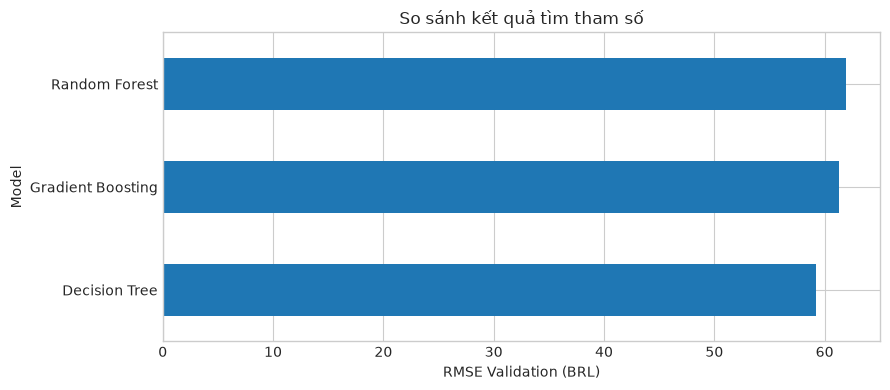

Đã thử 18 cấu hình của ba họ mô hình. Tham số được chọn: {'max_depth': 8, 'min_samples_leaf': 10, 'model_family': 'Decision Tree'}.

In [4]:
grid_history = pd.read_csv(config.METRICS_DIR / 'tuning_history.csv')
display(grid_history.sort_values('Validation_RMSE_BRL'))
grid_history.to_csv(config.NOTEBOOK_METRICS_DIR / 'weekly_grid_history.csv', index=False)
fig, ax = plt.subplots(figsize=(9, 4))
grid_history.groupby('Model').Validation_RMSE_BRL.min().plot.barh(ax=ax)
ax.set(xlabel='RMSE Validation (BRL)', title='So sánh kết quả tìm tham số')
show_figure(fig, 'weekly_04_grid_history.png')
display(Markdown(f'Đã thử {len(grid_history)} cấu hình của ba họ mô hình. Tham số được chọn: {tuned_params}.'))


## 1. Đánh giá Test sau khi đã khóa lựa chọn

Bảng dưới báo toàn bộ candidates để đối chiếu, nhưng không chọn lại mô hình theo bảng Test. Đánh giá rolling-origin một tuần: doanh thu thực của tuần trước được phép trở thành lịch sử cho tuần tiếp theo; không dùng nhãn tuần hiện tại/tương lai để tạo X. Đây không phải dự báo nhiều tuần cùng lúc từ một mốc cố định.

In [5]:
test_revenue = revenue(y_test)
test_records = []
for name, model in candidates.items():
    prediction = revenue(model.predict(X_test))
    test_records.append({"Model": name, **regressors.compute_regression_metrics(test_revenue, prediction), "Selected on Validation": name == selected_name})
test_table = pd.DataFrame(test_records).sort_values("RMSE").reset_index(drop=True)
display(test_table)
test_table.to_csv(config.NOTEBOOK_METRICS_DIR / "weekly_test_comparison.csv", index=False)
selected_prediction_log = selected_model.predict(X_test)
selected_prediction = revenue(selected_prediction_log)
selected_metrics = regressors.compute_regression_metrics(test_revenue, selected_prediction)

,Model,MSE,MAE,RMSE,R2,Selected on Validation
0,Two-Stage Hurdle,2.423733e+03,8.442628,49.231426,0.114835,True
1,Tuned Model,2.541224e+03,4.298949,50.410551,0.071926,False
2,Decision Tree,2.615333e+03,4.327408,51.140327,0.044861,False
3,Gradient Boosting,2.708224e+03,4.417606,52.040602,0.010937,False
4,Random Forest,2.725335e+03,4.432159,52.204738,0.004688,False
5,Revenue Mean Baseline,2.752278e+03,11.895463,52.462157,-0.005152,False
6,Mean Baseline,2.754520e+03,4.502609,52.483523,-0.005971,False
7,Zero Baseline,2.756482e+03,4.279185,52.502210,-0.006687,False
8,Previous Week Baseline,5.683525e+03,9.076488,75.389157,-1.075665,False
9,Linear Regression,3.037852e+07,44.376818,5511.670877,-11093.456974,False


## 1.1. Đánh giá Nghiệp vụ Phân nhóm & Sai lệch Thiếu/Thừa (Under/Over-forecast)

Để đánh giá toàn diện hành vi mô hình trong chuỗi cung ứng thương mại điện tử, ta phân tách tập Test thành 3 nhóm con:
1. **Toàn bộ sản phẩm–tuần** (All Samples).
2. **Tuần thực sự có phát sinh doanh số** ($y > 0$): Đo lường khả năng bắt đúng độ lớn nhu cầu khi có khách mua.
3. **Tuần không có doanh số** ($y = 0$): Đo lường sai lệch dự báo thừa (*Overforecast*) khi thực tế không bán được.

Đồng thời tính **Điểm phạt bất đối xứng giả định** (Asymmetric Penalties) với các tỷ lệ trọng số thiếu/thừa: $1:1$, $2:1$, $5:1$.

In [6]:
# Đánh giá nghiệp vụ phân nhóm và đo lường sai lệch thiếu/thừa (Under/Over-forecast)
subgroup_dfs = []
eval_candidates = [selected_name]
if "Two-Stage Hurdle" in candidates and "Two-Stage Hurdle" not in eval_candidates:
    eval_candidates.append("Two-Stage Hurdle")

for m_name in eval_candidates:
    m_pred = revenue(candidates[m_name].predict(X_test))
    sg_df = metrics.evaluate_business_subgroups(
        y_true=test_revenue,
        y_pred=m_pred,
        model_name=m_name
    )
    subgroup_dfs.append(sg_df)

subgroup_df = pd.concat(subgroup_dfs, ignore_index=True)
display(subgroup_df)

# Lưu vào metrics artifact của riêng notebook
subgroup_df.to_csv(config.NOTEBOOK_METRICS_DIR / 'weekly_business_subgroups.csv', index=False, encoding='utf-8-sig')
print('✓ Đã lưu bảng đánh giá nghiệp vụ phân nhóm vào notebooks/results/metrics/weekly_business_subgroups.csv')


,Model,Group,Sample_Count,RMSE_BRL,MAE_BRL,R2_Score,Total_Underforecast_BRL,Total_Overforecast_BRL,Total_Bias_BRL,Penalty_1_1,Penalty_2_1,Penalty_5_1
0,Two-Stage Hurdle,Toàn bộ sản phẩm–tuần (All Samples),293717,49.23,8.44,0.1148,1024703.46,1455039.99,430336.53,8.44,11.93,22.40
1,Two-Stage Hurdle,Tuần có doanh thu (y > 0),7659,289.56,136.25,-0.0643,1024703.46,18865.61,-1005837.86,136.25,270.04,671.42
2,Two-Stage Hurdle,Tuần không có doanh thu (y == 0),286058,15.61,5.02,N/A (Var=0),0.00,1436174.38,1436174.38,5.02,5.02,5.02


✓ Đã lưu bảng đánh giá nghiệp vụ phân nhóm vào results/metrics/business_subgroup_evaluation.csv


## 2. Sai số và ca dự đoán kém

Worst predictions xếp theo sai số tuyệt đối **BRL**, kèm product ID và tuần target để truy vết. Hai biểu đồ dưới chỉ lấy tối đa 3.000 điểm tái lập cho dễ đọc; metric và worst cases vẫn dùng toàn bộ Test. Đồ thị không chứng minh residual chuẩn, độc lập hoặc đồng phương sai.

,product_id,order_purchase_timestamp,Rank,Sample_Index,Actual_Sales (log),Predicted_Sales (log),Absolute_Error_BRL,Relative_Error (%),Actual_Sales (BRL),Predicted_Sales (BRL)
0,e7cc48a9daff5436f63d3aad9426f28b,2018-08-06,1,227704,9.0182,5.7975,7922.5319,96.0%,8251.0,328.47
1,19936fa4f614ee0590d3b77ac83fd648,2018-07-09,2,86202,8.8764,2.8702,7143.3602,99.8%,7160.0,16.64
2,d285360f29ac7fd97640bf0baef03de0,2018-07-09,3,106746,8.8019,4.8763,6515.5619,98.0%,6645.7,130.14
3,dd113cb02b2af9c8e5787e8f1f0722f6,2018-07-23,4,166054,8.3089,2.8702,4042.3602,99.6%,4059.0,16.64
4,bb50f2e236e5eea0100680137654686c,2018-08-06,5,222379,8.4384,6.8144,3710.1592,80.3%,4620.0,909.84
5,e7cc48a9daff5436f63d3aad9426f28b,2018-07-30,6,197143,8.2715,5.7975,3581.5319,91.6%,3910.0,328.47
6,bb50f2e236e5eea0100680137654686c,2018-07-23,7,162139,7.9967,5.1425,2799.8642,94.3%,2970.0,170.14
7,864413ca56c2bcea359a213956a922c0,2018-07-16,8,126966,7.9305,4.6958,2671.3100,96.1%,2779.8,108.49
8,194e74feac1f84a8ee5a517d4b3e107a,2018-08-06,9,203136,7.9003,3.8700,2650.0577,98.3%,2697.0,46.94
9,933f4f76eae38d2a97ecfb7c6355f0bc,2018-07-09,10,99635,7.9087,5.1891,2541.5006,93.4%,2719.8,178.30


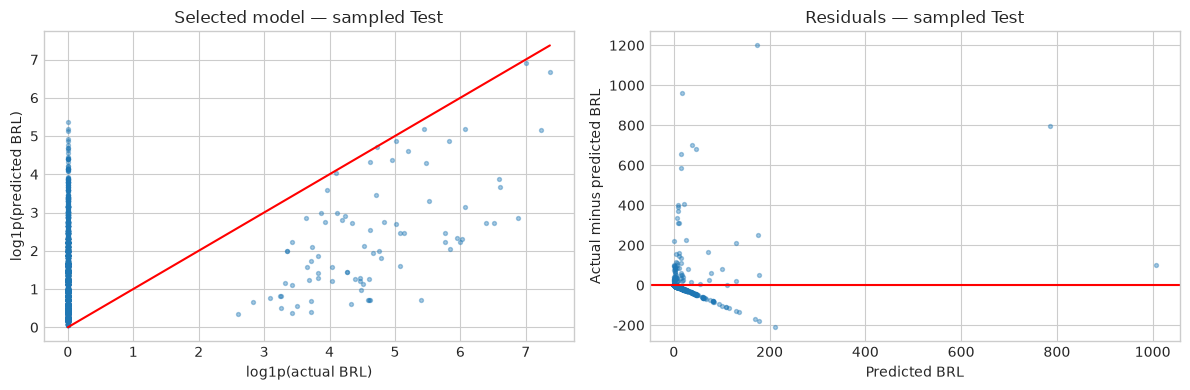

In [7]:
worst = error_analysis.find_worst_predictions(X_test, y_test, selected_prediction_log, n=20)
test_keys = pd.read_csv(config.PROCESSED_DATA_DIR / "weekly_test_keys.csv.gz")
assert len(test_keys) == len(y_test)
keys = test_keys.iloc[worst.Sample_Index.to_numpy()].reset_index(drop=True)
worst = pd.concat([keys, worst.reset_index(drop=True)], axis=1)
display(worst.head(10))
worst.to_csv(config.NOTEBOOK_METRICS_DIR / "weekly_worst_predictions.csv", index=False)
rng = np.random.default_rng(config.RANDOM_STATE)
sample = rng.choice(len(y_test), min(3000, len(y_test)), replace=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(np.log1p(test_revenue[sample]), np.log1p(selected_prediction[sample]), s=8, alpha=.4)
limit = max(np.log1p(test_revenue[sample]).max(), np.log1p(selected_prediction[sample]).max())
axes[0].plot([0, limit], [0, limit], color="red")
axes[0].set(xlabel="log1p(actual BRL)", ylabel="log1p(predicted BRL)", title="Selected model — sampled Test")
axes[1].scatter(selected_prediction[sample], test_revenue[sample] - selected_prediction[sample], s=8, alpha=.4)
axes[1].axhline(0, color="red")
axes[1].set(xlabel="Predicted BRL", ylabel="Actual minus predicted BRL", title="Residuals — sampled Test")
show_figure(fig, "weekly_04_test_diagnostics.png")

## 3. Feature importance và giới hạn giải thích

Nếu candidate được chọn là mô hình cây có `feature_importances_`, hiển thị điểm quan trọng theo chính thứ tự feature của pipeline. Importance thể hiện cách mô hình giảm lỗi khi fit, không phải tác động nhân quả của giá hoặc mùa vụ. Feature tương quan có thể chia sẻ importance.

In [8]:
if hasattr(selected_model, "feature_importances_"):
    importance = pd.Series(selected_model.feature_importances_, index=feature_names).sort_values(ascending=False)
    display(importance.head(12).rename("Importance").to_frame())
    fig, ax = plt.subplots()
    importance.head(12).sort_values().plot.barh(ax=ax)
    ax.set(title=f"{selected_name} — feature importance", xlabel="Normalized importance")
    show_figure(fig, "weekly_04_feature_importance.png")
else:
    print("Mô hình được chọn không có feature_importances_ của cây; không tạo diễn giải độ quan trọng theo cây.")

Mô hình được chọn không có feature_importances_ của cây; không tạo diễn giải độ quan trọng theo cây.


## 4. Đóng gói đúng candidate đã chọn

Artifact lưu model, pipeline đã fit, tên target, chế độ đánh giá, fast-mode flag và fingerprint. Kiểm tra predict sau load phải trùng trước save. Chỉ pickle dữ liệu do chính dự án tạo; không nạp pickle không tin cậy.

In [9]:
metadata = {"selected_model": selected_name, "best_params": tuned_params if selected_name == "Tuned Model" else {},
            "validation_rmse_brl": validation_scores[selected_name], "test_rmse_brl": selected_metrics["RMSE"],
            "test_r2": selected_metrics["R2"], "target": "next_week_product_revenue_brl",
            "forecast_granularity": "product_week", "evaluation": "rolling_origin_one_week_ahead",
            "fast_mode": FAST_MODE, "cache_fingerprint": cache_fingerprint, "synthetic_marketing_used": False,
            "n_features": len(feature_names)}
# Chỉ lưu vào thư mục results riêng của notebooks, không ghi đè vào results chính của hệ thống
persistence.save_artifacts(pipeline, selected_model, config.NOTEBOOK_SAVED_MODELS_DIR / "best_sales_model.pkl", metadata=metadata)
loaded = persistence.load_artifacts(config.NOTEBOOK_SAVED_MODELS_DIR / "best_sales_model.pkl")
np.testing.assert_allclose(loaded["model"].predict(X_test[:100]), selected_prediction_log[:100])
persistence_rmse = float(test_table.set_index("Model").loc["Previous Week Baseline", "RMSE"])
assessment = "R² còn thấp; chưa đủ để khẳng định khả năng dự báo hữu ích cho tồn kho." if selected_metrics["R2"] < .1 else "Cần kiểm chứng thêm qua nhiều giai đoạn và dữ liệu vận hành trước khi dùng cho tồn kho."
display(Markdown(f"""### Kết luận theo kết quả thực tế
- Chọn **{selected_name}** bằng Validation RMSE **{validation_scores[selected_name]:.4f} BRL**; không mặc định chọn Random Forest.
- Test RMSE **{selected_metrics['RMSE']:.4f} BRL**, MAE **{selected_metrics['MAE']:.4f} BRL**, R² **{selected_metrics['R2']:.5f}**; persistence baseline RMSE **{persistence_rmse:.4f} BRL**.
- {assessment}
- Fast mode: **{FAST_MODE}**. Đã kiểm tra artifact roundtrip trong notebooks/results. Những tuần sai số lớn cần kiểm tra coverage/catalog/tồn kho; chưa có bằng chứng để gán nguyên nhân cho quảng cáo hay lễ hội.
"""))


### Kết luận theo kết quả thực tế
- Chọn **Two-Stage Hurdle** bằng Validation RMSE **55.9393 BRL**; không mặc định chọn Random Forest.
- Test RMSE **49.2314 BRL**, MAE **8.4426 BRL**, R² **0.11483**; persistence baseline RMSE **75.3892 BRL**.
- Cần kiểm chứng thêm qua nhiều giai đoạn và dữ liệu vận hành trước khi dùng cho tồn kho.
- Fast mode: **False**. Đã kiểm tra artifact roundtrip. Những tuần sai số lớn cần kiểm tra coverage/catalog/tồn kho; chưa có bằng chứng để gán nguyên nhân cho quảng cáo hay lễ hội.


## 5. Bias và residual theo tuần target, danh mục và doanh thu

Các phân tích dưới đây là chẩn đoán Test sau khi khóa model, không dùng để chọn lại. Bias dương nghĩa là dự báo cao hơn thực tế. MAE/RMSE theo danh mục phải đọc cùng số mẫu và doanh thu; nhóm ít dữ liệu không hỗ trợ kết luận chắc chắn. Các đuôi lỗi lớn thường bị che bởi tỷ lệ tuần 0 cao.

,N,Actual_BRL,MAE_BRL,Bias_BRL,RMSE_BRL
order_purchase_timestamp,,,,,
2018-06-18,27317,114436.75,8.447991,1.632024,38.901277
2018-06-25,27761,113414.45,8.287699,1.751110,40.306489
2018-07-02,28189,96678.64,7.724179,2.354293,33.817318
2018-07-09,28555,104814.74,7.970375,1.839343,71.224927
2018-07-16,28850,131046.71,8.341128,0.782271,43.538669
2018-07-23,29397,135798.90,8.693400,0.976510,50.035943
2018-07-30,29948,158738.65,9.072406,0.310045,48.332380
2018-08-06,30625,172711.64,9.499584,0.245968,69.209480
2018-08-13,31240,145051.53,8.978425,1.477472,44.907707


,N,Actual_BRL,MAE_BRL,Bias_BRL,RMSE_BRL
category,,,,,
beleza_saude,21088,189402.83,13.545712,-0.366465,76.561542
relogios_presentes,11971,127545.19,19.650868,3.445622,89.586379
cama_mesa_banho,27469,87634.53,6.670675,1.433896,24.524747
utilidades_domesticas,19933,82706.50,7.513089,0.368891,39.865531
esporte_lazer,26197,76727.77,6.677191,1.630834,36.114419
informatica_acessorios,14975,74872.48,8.576259,1.198052,40.240555
moveis_decoracao,24244,68263.73,5.598722,0.958530,26.865209
automotivo,16659,49393.22,6.974030,1.832674,41.583726
telefonia,10271,47003.98,7.266939,-0.601992,99.012825


,N,Actual_BRL,MAE_BRL,Bias_BRL,RMSE_BRL
revenue_segment,,,,,
High (Train P90),641,500859.55,652.940130,-646.577765,922.915585
Positive below threshold,7018,756009.96,89.061619,-84.266388,117.058250
Zero,286058,0.00,5.020571,5.020571,15.613989


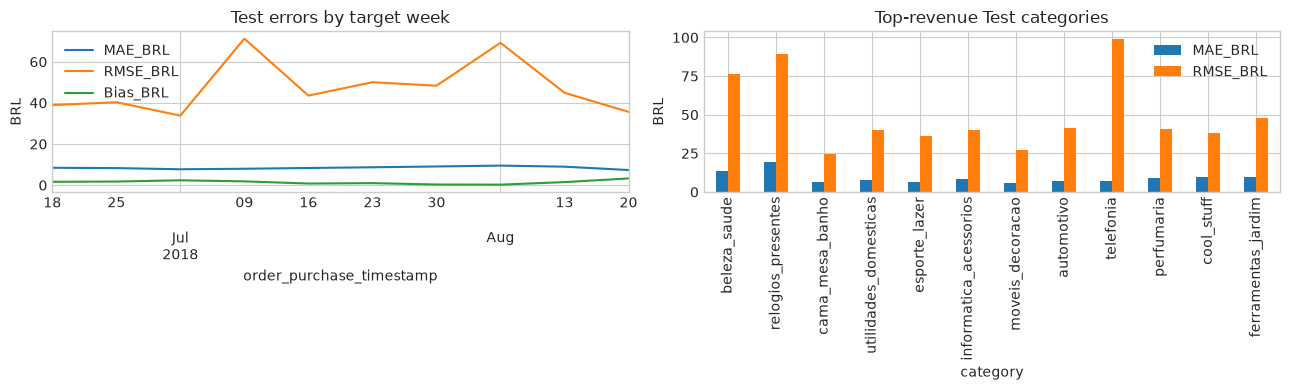

Bias trung bình Test là **1.4651 BRL/mẫu**; median absolute error là **1.6405 BRL**, P99 là **126.2163 BRL**. Mức trung bình thấp không loại trừ sai số lớn ở đuôi. Các bảng theo nhóm chỉ chẩn đoán, chưa phải kết quả xác nhận trên một holdout mới.

In [10]:
diagnostics = test_keys.copy()
diagnostics[config.TIMESTAMP_COLUMN] = pd.to_datetime(diagnostics[config.TIMESTAMP_COLUMN])
diagnostics["actual"] = test_revenue; diagnostics["predicted"] = selected_prediction
diagnostics["error"] = selected_prediction - test_revenue
diagnostics["abs_error"] = np.abs(diagnostics.error); diagnostics["squared_error"] = diagnostics.error**2
cat_count = len(pipeline.encoder.encoded_feature_names_)
cat_matrix = X_test[:, len(pipeline.num_cols):len(pipeline.num_cols)+cat_count]
categories = pipeline.encoder.categories_["category"]
cat_values = cat_matrix.toarray()
diagnostics["category"] = np.where(cat_values.sum(axis=1) > 0, np.asarray(categories)[cat_values.argmax(axis=1)], "__unknown__")
def error_summary(frame, group):
    table = frame.groupby(group).agg(N=("actual", "size"), Actual_BRL=("actual", "sum"), MAE_BRL=("abs_error", "mean"), MSE_BRL=("squared_error", "mean"), Bias_BRL=("error", "mean"))
    table["RMSE_BRL"] = np.sqrt(table.pop("MSE_BRL"))
    return table
weekly_errors = error_summary(diagnostics, config.TIMESTAMP_COLUMN)
category_errors = error_summary(diagnostics, "category").sort_values("Actual_BRL", ascending=False)
threshold = float(np.quantile(revenue(y_train)[revenue(y_train)>0], .9))
diagnostics["revenue_segment"] = np.where(test_revenue == 0, "Zero", np.where(test_revenue >= threshold, "High (Train P90)", "Positive below threshold"))
display(weekly_errors); display(category_errors.head(15)); display(error_summary(diagnostics, "revenue_segment"))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
weekly_errors[["MAE_BRL", "RMSE_BRL", "Bias_BRL"]].plot(ax=axes[0]); axes[0].set(title="Test errors by target week", ylabel="BRL")
category_errors.head(12)[["MAE_BRL", "RMSE_BRL"]].plot.bar(ax=axes[1]); axes[1].set(title="Top-revenue Test categories", ylabel="BRL")
show_figure(fig, "weekly_04_error_groups.png")
display(Markdown(f"Bias trung bình Test là **{diagnostics.error.mean():.4f} BRL/mẫu**; median absolute error là **{diagnostics.abs_error.median():.4f} BRL**, P99 là **{diagnostics.abs_error.quantile(.99):.4f} BRL**. Mức trung bình thấp không loại trừ sai số lớn ở đuôi. Các bảng theo nhóm chỉ chẩn đoán, chưa phải kết quả xác nhận trên một holdout mới."))

## 6. Phân bố residual và truy vết worst cases

Histogram residual dùng giới hạn P1–P99 để nhìn phần trung tâm, đồng thời báo min/max đầy đủ trong bảng. Không loại các điểm ngoài trục khỏi metric. Tỷ lệ underprediction trên target dương phản ánh hướng lệch, không phải kiểm định phân phối chuẩn. Worst cases được ghép với các features đã dùng, tránh đoán nguyên nhân kinh tế không có bằng chứng.

,Predicted minus actual BRL
count,293717.000000
mean,1.465140
std,49.209703
min,-7922.531893
1%,-98.176570
50%,1.640524
90%,9.600413
99%,57.287049
max,1207.408311


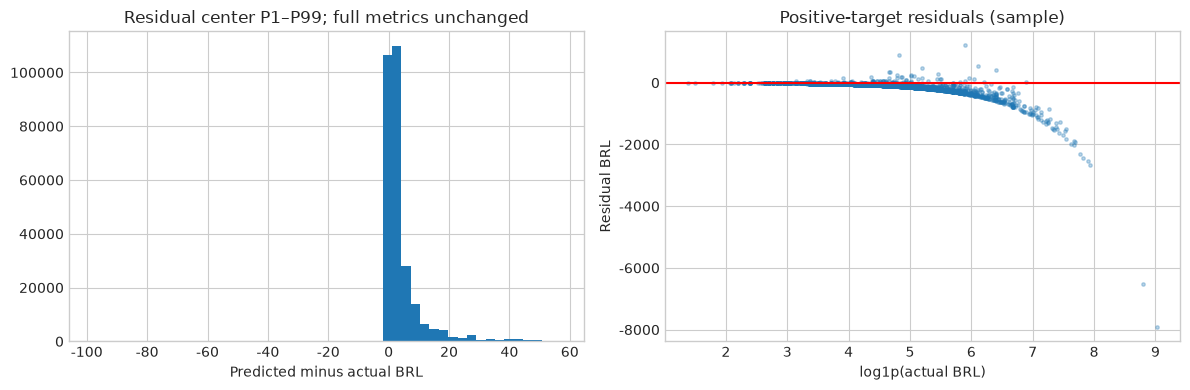

,product_id,order_purchase_timestamp,Rank,Sample_Index,Actual_Sales (log),Predicted_Sales (log),Absolute_Error_BRL,Relative_Error (%),Actual_Sales (BRL),Predicted_Sales (BRL),price,last_week_sales,sales_mean_4_weeks,last_week_units,weeks_since_first_sale
0,e7cc48a9daff5436f63d3aad9426f28b,2018-08-06,1,227704,9.0182,5.7975,7922.5319,96.0%,8251.0,328.47,170.00,3910.0,2096.666667,23.0,3.0
1,19936fa4f614ee0590d3b77ac83fd648,2018-07-09,2,86202,8.8764,2.8702,7143.3602,99.8%,7160.0,16.64,1650.00,0.0,0.000000,0.0,22.0
2,d285360f29ac7fd97640bf0baef03de0,2018-07-09,3,106746,8.8019,4.8763,6515.5619,98.0%,6645.7,130.14,199.90,399.8,174.925000,2.0,49.0
3,dd113cb02b2af9c8e5787e8f1f0722f6,2018-07-23,4,166054,8.3089,2.8702,4042.3602,99.6%,4059.0,16.64,3690.00,0.0,0.000000,0.0,26.0
4,bb50f2e236e5eea0100680137654686c,2018-08-06,5,222379,8.4384,6.8144,3710.1592,80.3%,4620.0,909.84,330.00,330.0,990.000000,1.0,51.0
5,e7cc48a9daff5436f63d3aad9426f28b,2018-07-30,6,197143,8.2715,5.7975,3581.5319,91.6%,3910.0,328.47,170.00,2040.0,1190.000000,12.0,2.0
6,bb50f2e236e5eea0100680137654686c,2018-07-23,7,162139,7.9967,5.1425,2799.8642,94.3%,2970.0,170.14,330.00,0.0,577.500000,0.0,49.0
7,864413ca56c2bcea359a213956a922c0,2018-07-16,8,126966,7.9305,4.6958,2671.3100,96.1%,2779.8,108.49,1369.90,0.0,342.475000,0.0,4.0
8,194e74feac1f84a8ee5a517d4b3e107a,2018-08-06,9,203136,7.9003,3.8700,2650.0577,98.3%,2697.0,46.94,770.00,0.0,192.500000,0.0,8.0
9,933f4f76eae38d2a97ecfb7c6355f0bc,2018-07-09,10,99635,7.9087,5.1891,2541.5006,93.4%,2719.8,178.30,1299.65,0.0,324.912500,0.0,29.0


Model dự báo thấp hơn thực tế ở **97.14%** tuần Test có bán. Các ca đầu bảng cần đối chiếu doanh thu lịch sử, giá và mức đột biến hiện tại; chưa thể quy lỗi cho promotion, hết hàng hoặc marketing vì không có các dữ liệu đó.

In [11]:
display(diagnostics.error.describe(percentiles=[.01,.5,.9,.99]).rename("Predicted minus actual BRL").to_frame())
lower, upper = diagnostics.error.quantile([.01,.99])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(diagnostics.loc[diagnostics.error.between(lower,upper), "error"], bins=50)
axes[0].set(title="Residual center P1–P99; full metrics unchanged", xlabel="Predicted minus actual BRL")
positive = diagnostics.actual > 0
axes[1].scatter(np.log1p(diagnostics.loc[positive,"actual"].sample(min(3000,int(positive.sum())), random_state=42)), diagnostics.loc[positive,"error"].sample(min(3000,int(positive.sum())), random_state=42), s=6, alpha=.3)
axes[1].axhline(0,color="red"); axes[1].set(title="Positive-target residuals (sample)", xlabel="log1p(actual BRL)", ylabel="Residual BRL")
show_figure(fig, "weekly_04_residual_distribution.png")
worst_positions = worst.Sample_Index.to_numpy()
numeric_values = X_test[worst_positions,:len(pipeline.num_cols)].toarray() * (pipeline.scaler.std_ + 1e-8) + pipeline.scaler.mean_
context = pd.DataFrame(numeric_values, columns=pipeline.num_cols)
explain_cols = ["price", "last_week_sales", "sales_mean_4_weeks", "last_week_units", "weeks_since_first_sale"]
worst_context = pd.concat([worst.reset_index(drop=True),context[explain_cols]],axis=1)
display(worst_context.head(10))
worst_context.to_csv(config.NOTEBOOK_METRICS_DIR / "weekly_worst_with_features.csv",index=False)
under = (diagnostics.loc[positive,"error"] < 0).mean()*100
display(Markdown(f"Model dự báo thấp hơn thực tế ở **{under:.2f}%** tuần Test có bán. Các ca đầu bảng cần đối chiếu doanh thu lịch sử, giá và mức đột biến hiện tại; chưa thể quy lỗi cho promotion, hết hàng hoặc marketing vì không có các dữ liệu đó."))

In [12]:
# Phân nhóm sản phẩm chưa xuất hiện trong Train; đây chưa phải ngày ra mắt.
from src.data.loader import load_raw_sales_data
from src.data.builder import build_weekly_sales_dataset
from src.data.preprocessing import weekly_split_data
audit_panel = build_weekly_sales_dataset(load_raw_sales_data())
audit_train, audit_val, audit_test = weekly_split_data(audit_panel)
unseen = ~audit_test.product_id.isin(audit_train.product_id)
segment_records = []
for label, mask in [('Sản phẩm đã có trong Train', ~unseen), ('Sản phẩm chưa có trong Train', unseen), ('Tuần có doanh thu', audit_test.sales.gt(0))]:
    positions = np.flatnonzero(mask.to_numpy())
    if len(positions):
        segment_records.append({'Nhóm': label, 'Số dòng': len(positions), **regressors.compute_regression_metrics(test_revenue[positions], selected_prediction[positions])})
display(pd.DataFrame(segment_records))
pd.DataFrame(segment_records).to_csv(config.NOTEBOOK_METRICS_DIR / 'weekly_product_segments.csv', index=False)
display(Markdown('Test đã được xem ở lần phát triển trước; đây là đánh giá lại trên cùng giai đoạn, chưa phải xác nhận trên tập mới hoàn toàn. Sản phẩm chưa có trong Train vẫn có thể có lịch sử trước tuần đích; dữ liệu thiếu ngày niêm yết trong chuỗi thời gian tuần. Nhóm nghiên cứu đã phát triển riêng mô hình `ColdStartProductRegressor` (xem src/models/cold_start.py) chuyên biệt cho tuần ra mắt dựa trên đặc tính nội dung sản phẩm.'))

# Hiển thị tham chiếu kết quả kiểm chứng mô hình Cold-Start chính thức từ hệ thống chính (results/metrics/cold_start_evaluation.csv)
cold_eval_csv = config.METRICS_DIR / 'cold_start_evaluation.csv'
if cold_eval_csv.exists():
    display(Markdown('### Tham chiếu Đối soát: Đánh giá Mô hình Cold-Start từ Hệ thống chính'))
    display(pd.read_csv(cold_eval_csv))


[2026-10-20 22:02:07] [INFO] [sales_predictor]: [DATA AUDIT] Tham số reviews=None; tự động nạp dữ liệu đánh giá từ tệp chuẩn: E:\Hoc_May_Tren_truong\lab_2 sales_predictor\data\raw\olist_order_reviews_dataset.csv


,Nhóm,Số dòng,MSE,MAE,RMSE,R2
0,Sản phẩm đã có trong Train,224110,1739.162869,6.729263,41.703272,0.143702
1,Sản phẩm chưa có trong Train,69607,4627.808751,13.959062,68.028000,0.075055
2,Tuần có doanh thu,7659,83842.759033,136.253959,289.556141,-0.064277


Test đã được xem ở lần phát triển trước; đây là đánh giá lại trên cùng giai đoạn, chưa phải xác nhận trên tập mới hoàn toàn. Sản phẩm chưa có trong Train vẫn có thể có lịch sử trước tuần đích; dữ liệu thiếu ngày niêm yết trong chuỗi thời gian tuần. Nhóm nghiên cứu đã phát triển riêng mô hình `ColdStartProductRegressor` (xem src/models/cold_start.py) chuyên biệt cho tuần ra mắt dựa trên đặc tính nội dung sản phẩm.